## 1. Data loading and project paths
Load market and trade CSVs and inspect dataset dimensions.


In [2]:
## 1. Load datasets
from pathlib import Path

import pandas as pd

# Set the project root relative to this notebook's location.
PROJECT_ROOT = Path("../../")

# Define the directory containing the raw extension dataset.
DATA_DIR = PROJECT_ROOT / "data" / "extension data" / "raw"

# Define the paths to the market and trade CSV files.
MARKETS_PATH = DATA_DIR / "markets.csv"
TRADES_PATH = DATA_DIR / "trades.csv"

# Load the market-level and trade-level datasets into pandas DataFrames.
markets = pd.read_csv(MARKETS_PATH)
trades = pd.read_csv(TRADES_PATH)

# Display the number of rows and columns in each dataset.
print(f"Markets shape: {markets.shape}")
print(f"Trades shape: {trades.shape}")


Markets shape: (529307, 20)
Trades shape: (65017902, 8)


## 2. Market metadata and category distributions
Inspect missing values and distributions of market type, status, and result.


In [3]:
import matplotlib.pyplot as plt

# Count categories and missing values.
category_columns = ["market_type", "status", "result"]

display(pd.DataFrame({
    "Distinct categories": markets[category_columns].nunique(),
    "Missing rows": markets[category_columns].isna().sum(),
}))

# Show the number of markets in each category.
for column in category_columns:
    print(f"\n{column}")
    display(
        markets[column]
        .fillna("Missing")
        .value_counts()
        .rename("Markets")
        .to_frame()
    )



,Distinct categories,Missing rows
market_type,1,0
status,6,0
result,2,31788



market_type


,Markets
market_type,
binary,529307



status


,Markets
status,
finalized,497883
active,31165
closed,161
inactive,89
determined,8
disputed,1



result


,Markets
result,
no,379732
yes,117787
Missing,31788


## 3. Market-series concentration
Use ticker prefixes to identify market series and visualize the largest groups.



Distinct market series: 4,679


,Markets,Share of all markets (%)
ticker,,
KXMVENFLMULTIGAMEEXTENDED,132111,24.96
KXMVENFLSINGLEGAME,90685,17.13
KXBTCD,43526,8.22
KXBTC,30162,5.70
KXMVESPORTSMULTIGAMEEXTENDED,24212,4.57
KXETHD,17530,3.31
KXNASDAQ100U,15385,2.91
KXETH,14262,2.69
KXINXU,13611,2.57


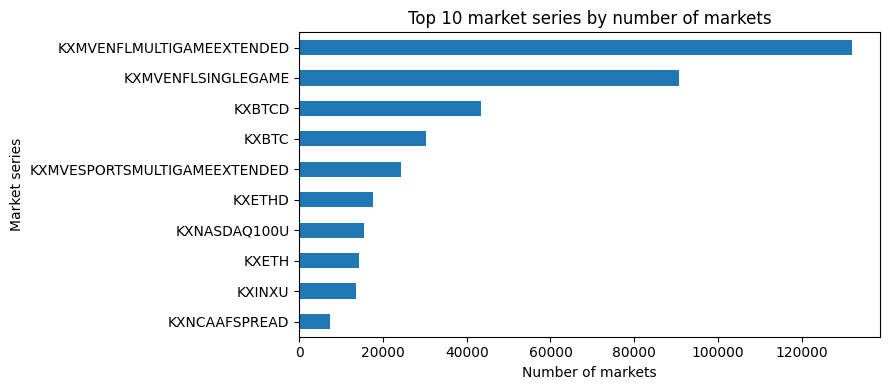

Largest series: 25.0% of markets
Top 10 series combined: 73.5% of markets


In [4]:
# There is no topic-category column, so use ticker prefixes as series groups.
# These are market series, not broad topics such as sports or politics.
market_series = markets["ticker"].str.split("-", n=1).str[0]
series_counts = market_series.value_counts()

print(f"\nDistinct market series: {market_series.nunique():,}")

# Display the 10 largest series.
top_series = series_counts.head(10).rename("Markets").to_frame()
top_series["Share of all markets (%)"] = (
    top_series["Markets"] / len(markets) * 100
).round(2)

display(top_series)

# Plot the 10 largest series.
top_series["Markets"].sort_values().plot.barh(figsize=(9, 4))
plt.title("Top 10 market series by number of markets")
plt.xlabel("Number of markets")
plt.ylabel("Market series")
plt.tight_layout()
plt.show()

# Simple conclusions about concentration.
print(f"Largest series: {series_counts.iloc[0] / len(markets):.1%} of markets")
print(f"Top 10 series combined: {series_counts.head(10).sum() / len(markets):.1%} of markets")


## 4. Human-readable series labels
Define descriptive labels for selected ticker prefixes and common sports series.


In [5]:
# Add or adjust names here as we review more series.
series_names = {
    "KXBTC": "Bitcoin — price range",
    "KXBTCD": "Bitcoin — price threshold",
    "KXETH": "Ethereum — price range",
    "KXETHD": "Ethereum — price threshold",
    "KXDOGE": "Dogecoin — price range",
    "KXDOGED": "Dogecoin — price threshold",
    "KXXRPD": "XRP (Ripple) — price threshold",
    "KXSHIBA": "Shiba Inu — price range",
    "KXSHIBAD": "Shiba Inu — price threshold",
    "KXNASDAQ100": "Nasdaq-100 — price level",
    "KXNASDAQ100U": "Nasdaq-100 — above a price level",
    "KXINX": "S&P 500 — price level",
    "KXINXU": "S&P 500 — above a price level",
    "KXMVENFLMULTIGAMEEXTENDED": "NFL — multi-game combinations (extended)",
    "KXMVENFLMULTIGAME": "NFL — multi-game combinations",
    "KXMVENFLSINGLEGAME": "NFL — single-game combinations",
    "KXMVENBASINGLEGAME": "NBA — single-game combinations",
    "KXMVESPORTSMULTIGAMEEXTENDED": "Sports — multi-game combinations (extended)",
    "KXNFLANYTD": "NFL — anytime touchdown scorer",
    "KXNFLFIRSTTD": "NFL — first touchdown scorer",
    "KXNFL2TD": "NFL — two or more touchdowns",
    "KXNFLRECYDS": "NFL — receiving yards",
    "KXNFLRSHYDS": "NFL — rushing yards",
    "KXNFLPASSYDS": "NFL — passing yards",
    "KXNFLREC": "NFL — receptions",
    "KXNFLWINS": "NFL — season wins",
    "KXPGATOUR": "Golf — PGA Tour winner",
    "KXATPMATCH": "Tennis — ATP match winner",
    "KXWTAMATCH": "Tennis — WTA match winner",
    "KXHIGHDEN": "Weather — Denver high temperature",
    "KXHIGHAUS": "Weather — Austin high temperature",
    "KXHIGHCHI": "Weather — Chicago high temperature",
    "KXHIGHNY": "Weather — New York City high temperature",
    "KXHIGHPHIL": "Weather — Philadelphia high temperature",
    "KXHIGHMIA": "Weather — Miami high temperature",
    "KXHIGHLAX": "Weather — Los Angeles high temperature",
    "KXTRUMPMENTION": "Donald Trump — words mentioned",
    "KXTRUMPMENTIONB": "Donald Trump — words mentioned (series B)",
    "KXSECPRESSMENTION": "White House press secretary — words mentioned",
    "KXSPOTIFYD": "Spotify — top US song",
    "KXSPOTIFY2D": "Spotify — top US song (alternate series)",
    "KXSPOTIFYGLOBALD": "Spotify — top global song",
    "KXAPPRANKFREE": "Apps — top free US iPhone app",
    "KXAPPRANKFREE2": "Apps — second-ranked free US iPhone app",
    "KXOSCARWINNERS": "Oscars — winner combinations",
    "KXMARMAD": "College basketball — national champion",
}

# Expand common sports patterns.
leagues = {
    "NFL": "NFL",
    "NBA": "NBA",
    "WNBA": "WNBA",
    "MLB": "MLB",
    "NHL": "NHL",
    "MLS": "MLS",
    "NCAAF": "College football",
    "NCAAMB": "Men's college basketball",
}

for league, name in leagues.items():
    descriptions = {
        "GAME": "game winner",
        "SPREAD": "point spread",
        "TOTAL": "total points",
    }

    if league == "MLB":
        descriptions.update(SPREAD="run spread", TOTAL="total runs")
    elif league in ["NHL", "MLS"]:
        descriptions.update(SPREAD="goal spread", TOTAL="total goals")

    for suffix, description in descriptions.items():
        series_names[f"KX{league}{suffix}"] = f"{name} — {description}"



## 5. Series lookup and coverage
Create a series-level reference table, evaluate label coverage, and export the lookup CSV.


In [6]:
# Create one row for every ticker prefix.
series_lookup = (
    markets.assign(series=markets["ticker"].str.split("-", n=1).str[0])
    .groupby("series")
    .agg(
        markets=("ticker", "size"),
        example_title=("title", "first"),
    )
    .sort_values("markets", ascending=False)
    .reset_index()
)

series_lookup["readable_name"] = series_lookup["series"].map(series_names)

series_lookup["label_status"] = (
    series_lookup["readable_name"]
    .notna()
    .map({True: "Inferred label", False: "Needs review"})
)

# Use an example market title when a series has no assigned name.
series_lookup["readable_name"] = series_lookup["readable_name"].fillna(
    series_lookup["example_title"]
)

series_lookup["share_pct"] = (
    series_lookup["markets"] / len(markets) * 100
).round(2)

series_lookup = series_lookup[
    [
        "series",
        "readable_name",
        "label_status",
        "markets",
        "share_pct",
        "example_title",
    ]
]

display(series_lookup.head(30))

labeled = series_lookup["label_status"].eq("Inferred label")

print(f"Named series: {labeled.sum():,} of {len(series_lookup):,}")
print(
    f"Share of market rows with a name: "
    f"{series_lookup.loc[labeled, 'markets'].sum() / len(markets):.1%}"
)

# Save all series for review.
lookup_path = PROJECT_ROOT / "output" / "eda" / "market_series_names.csv"
lookup_path.parent.mkdir(parents=True, exist_ok=True)
series_lookup.to_csv(lookup_path, index=False)

print(f"Full lookup saved to: {lookup_path}")


,series,readable_name,label_status,markets,share_pct,example_title
0,KXMVENFLMULTIGAMEEXTENDED,NFL — multi-game combinations (extended),Inferred label,132111,24.96,"yes Detroit,yes Seattle,yes Jalen Nailor: 10+"
1,KXMVENFLSINGLEGAME,NFL — single-game combinations,Inferred label,90685,17.13,"yes Bijan Robinson,yes Tyler Shough: 175+,yes ..."
2,KXBTCD,Bitcoin — price threshold,Inferred label,43526,8.22,"Bitcoin price on Nov 17, 2025?"
3,KXBTC,Bitcoin — price range,Inferred label,30162,5.70,"Bitcoin price range on Nov 17, 2025?"
4,KXMVESPORTSMULTIGAMEEXTENDED,Sports — multi-game combinations (extended),Inferred label,24212,4.57,"yes New Orleans wins by over 2.5 points,yes La..."
5,KXETHD,Ethereum — price threshold,Inferred label,17530,3.31,"Ethereum price at Nov 17, 2025 at 5pm EST?"
6,KXNASDAQ100U,Nasdaq-100 — above a price level,Inferred label,15385,2.91,Will the Nasdaq-100 be above 25599.99 at the e...
7,KXETH,Ethereum — price range,Inferred label,14262,2.69,"Ethereum price at Nov 17, 2025 at 5pm EST?"
8,KXINXU,S&P 500 — above a price level,Inferred label,13611,2.57,"Will the S&P 500 be above 6824.9999 on Nov 17,..."
9,KXNCAAFSPREAD,College football — point spread,Inferred label,7377,1.39,Ohio St. wins by over 10.5 points?


Named series: 66 of 4,679
Share of market rows with a name: 91.6%
Full lookup saved to: ../../output/eda/market_series_names.csv


## 6. Category summaries and visualization
Apply the inferred labels to markets and inspect the resulting category distribution.


,Markets,Share (%)
category,,
NFL — multi-game combinations (extended),132111,24.96
NFL — single-game combinations,90685,17.13
Bitcoin — price threshold,43526,8.22
Bitcoin — price range,30162,5.70
Sports — multi-game combinations (extended),24212,4.57
Ethereum — price threshold,17530,3.31
Nasdaq-100 — above a price level,15385,2.91
Ethereum — price range,14262,2.69
S&P 500 — above a price level,13611,2.57


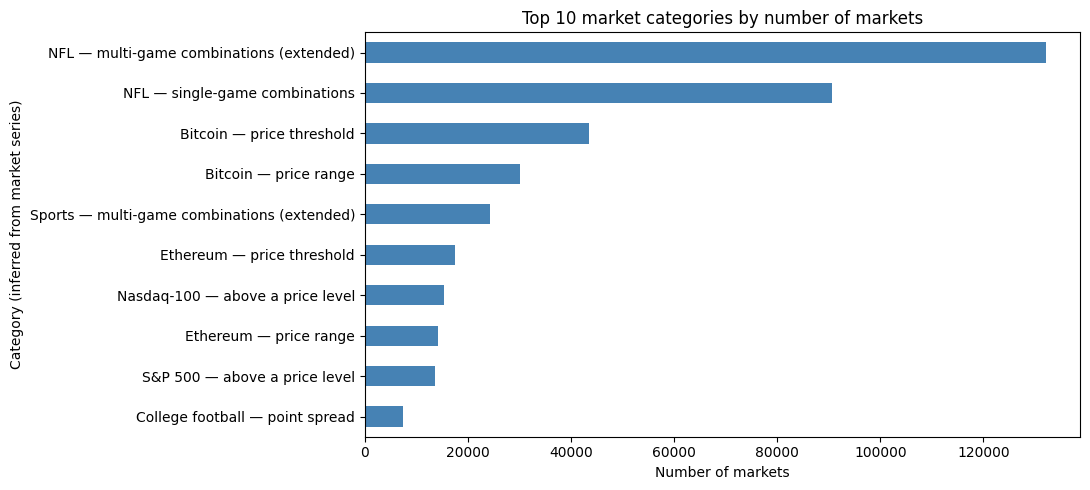

Distinct categories: 4,679
Largest category: 25.0% of markets
Top 10 combined: 73.5% of markets


,series,title
1620,KXCHILEROUNDONESECOND,Will José Antonio Kast finish 2nd in Chile?
2476,KXMVEMENTIONSSINGLE,yes: Mike Tirico and/or Cris Collinsworth says...
4683,KXDAVISCUPMATCH,Will Pablo Carreno Busta win the Berrettini vs...
5585,KXSPOTIFYARTISTD,"Top USA Artist on Spotify on Nov 17, 2025?"
11310,KXEURUSDH,Will the EUR/USD open price be above 1.15199 a...
...,...,...
529283,KX538CALL,Will 538 correctly call the presidential elect...
529284,CABINETRONPAUL,Ron Paul nominated to the Cabinet before Feb 1...
529285,TOPALBUMCHAPPELL,Chappell Roan has a #1 album in 2024?
529286,1SONGCHAPPELLROAN,"Will Chappell Roan have a #1 hit by Dec 28, 2024?"


In [7]:
import matplotlib.pyplot as plt

# Append readable categories; keep unnamed series as their original ticker.
markets["series"] = markets["ticker"].str.split("-", n=1).str[0]
markets["category"] = (
    markets["series"]
    .map(series_names)
    .fillna(markets["series"])
    .fillna("Unknown")
)

# Count markets per category.
category_counts = markets["category"].value_counts()

category_summary = category_counts.rename("Markets").to_frame()
category_summary["Share (%)"] = (
    category_summary["Markets"] / len(markets) * 100
).round(2)

display(category_summary.head(10))

# Regenerate the figure with readable labels.
ax = category_counts.head(10).sort_values().plot.barh(
    figsize=(11, 5),
    color="steelblue",
)

ax.set_title("Top 10 market categories by number of markets")
ax.set_xlabel("Number of markets")
ax.set_ylabel("Category (inferred from market series)")

plt.tight_layout()
plt.show()

print(f"Distinct categories: {category_counts.size:,}")
print(f"Largest category: {category_counts.iloc[0] / len(markets):.1%} of markets")
print(f"Top 10 combined: {category_counts.head(10).sum() / len(markets):.1%} of markets")
markets.loc[
    ~markets["series"].isin(series_names),
    ["series", "title"],
].drop_duplicates("series")


## 7. Maker and taker gross excess returns
Match trades to finalized YES/NO outcomes and aggregate gross excess returns in chunks.


In [8]:
resolved = markets.loc[
    markets["status"].eq("finalized") & markets["result"].isin(["yes", "no"])
].set_index("ticker")["result"]

maker_total = taker_total = n = 0

for t in pd.read_csv(
    TRADES_PATH,
    usecols=["ticker", "taker_side", "yes_price", "no_price"],
    chunksize=500_000,
):
    t["result"] = t["ticker"].map(resolved)
    t = t[t["result"].notna() & t["taker_side"].isin(["yes", "no"])]
    yes = t["taker_side"].eq("yes")
    won = t["taker_side"].eq(t["result"]).astype(float)

    taker_total += (won - t["yes_price"].where(yes, t["no_price"]) / 100).sum()
    maker_total += (1 - won - t["no_price"].where(yes, t["yes_price"]) / 100).sum()
    n += len(t)

if n:
    print(f"Maker gross excess return: {maker_total / n:+.2%}")
    print(f"Taker gross excess return: {taker_total / n:+.2%}")
    print(f"Matched resolved trades: {n:,}")
else:
    print("No trades matched finalized markets.")


Maker gross excess return: +1.25%
Taker gross excess return: -1.24%
Matched resolved trades: 60,677,581


## 7a. Abridged original analysis on our subset
Before the prediction extension, check whether the original descriptive patterns appear in our data.
We reuse the finalized YES/NO markets from section 7 and count both counterparties at their own purchase prices.
Calibration and maker/taker returns give each trade row equal weight, as in the author's
[`win_rate_by_price.py`](../../src/analysis/kalshi/win_rate_by_price.py),
[`mispricing_by_price.py`](../../src/analysis/kalshi/mispricing_by_price.py), and
[`maker_vs_taker_returns.py`](../../src/analysis/kalshi/maker_vs_taker_returns.py).
The YES/NO comparison weights by contract count, following
[`ev_yes_vs_no.py`](../../src/analysis/kalshi/ev_yes_vs_no.py), but keeps our finalized-market filter.

These are full-subset descriptive checks, separate from the later train/test evaluation.
A pattern can weaken or reverse in this subset. These plots do not establish statistical significance:
trades within a market share an outcome. All returns exclude fees and are settlement payout minus
purchase price per $1 payout, rather than percentage return on invested capital.

In [ ]:
# Keep only small grouped totals from each chunk; do not duplicate the full trade table.
baseline_parts = []
baseline_rows = baseline_matched = 0
assert resolved.index.is_unique, "Market tickers must be unique."

for chunk in pd.read_csv(
    TRADES_PATH,
    usecols=["ticker", "taker_side", "yes_price", "no_price", "count"],
    chunksize=500_000,
):
    baseline_rows += len(chunk)
    chunk["result"] = chunk["ticker"].map(resolved)
    chunk = chunk.loc[
        chunk["result"].notna() & chunk["taker_side"].isin(["yes", "no"])
    ].copy()
    baseline_matched += len(chunk)
    assert chunk[["yes_price", "no_price"]].notna().all().all()
    assert chunk[["yes_price", "no_price"]].ge(0).all().all()
    assert chunk[["yes_price", "no_price"]].le(100).all().all()
    assert chunk["count"].notna().all() and chunk["count"].gt(0).all()

    for role in ["Taker", "Maker"]:
        side = chunk["taker_side"]
        if role == "Maker":
            side = side.map({"yes": "no", "no": "yes"})
        positions = pd.DataFrame({
            "side": side,
            "price": chunk["yes_price"].where(side.eq("yes"), chunk["no_price"]),
            "won": side.eq(chunk["result"]).astype(int),
            "contracts": chunk["count"],
        })
        positions["winning_contracts"] = positions["won"] * positions["contracts"]
        totals = positions.groupby(["side", "price"]).agg(
            trades=("won", "size"), wins=("won", "sum"),
            contracts=("contracts", "sum"), winning_contracts=("winning_contracts", "sum"),
        ).reset_index()
        totals["role"] = role
        baseline_parts.append(totals)

baseline = pd.concat(baseline_parts).groupby(["role", "side", "price"])[
    ["trades", "wins", "contracts", "winning_contracts"]
].sum().reset_index()
assert baseline_matched > 0, "No trades matched finalized markets."
print(f"Matched {baseline_matched:,} of {baseline_rows:,} trade rows ({baseline_matched / baseline_rows:.1%}).")
print("Each matched trade contributes one maker and one taker position.")

by_price = baseline.groupby(["role", "price"])[["trades", "wins"]].sum()
by_price["win_rate"] = 100 * by_price["wins"] / by_price["trades"]
by_price["excess_pp"] = by_price["win_rate"] - by_price.index.get_level_values("price")
combined = baseline.groupby("price")[["trades", "wins"]].sum()
combined["win_rate"] = 100 * combined["wins"] / combined["trades"]
combined["excess_pp"] = combined["win_rate"] - combined.index

display(by_price.groupby("role").apply(
    lambda group: pd.Series({
        "Positions": group["trades"].sum(),
        "Gross excess return (pp)": (group["excess_pp"] * group["trades"]).sum() / group["trades"].sum(),
    }), include_groups=False,
).round(3))

Matched 60,677,581 of 65,017,902 trade rows (93.3%).
Each matched trade contributes one maker and one taker position.


,Positions,Gross excess return (pp)
role,,
Maker,60677581.0,1.248
Taker,60677581.0,-1.245


### Calibration: observed win rate versus purchase price
The diagonal represents perfect calibration. Below the diagonal, positions win less often than their prices imply.
Both counterparties are included, so the observations are paired rather than independent.

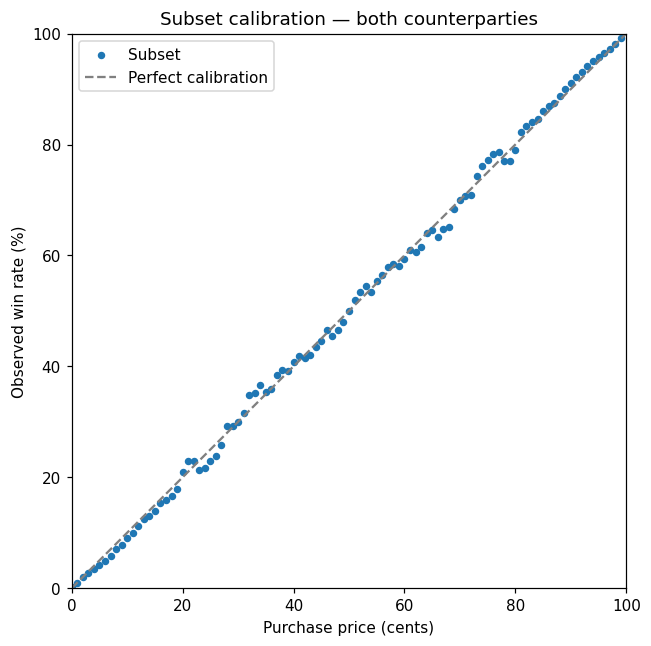

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(combined.index, combined["win_rate"], s=15, label="Subset")
ax.plot([0, 100], [0, 100], "--", color="gray", label="Perfect calibration")
ax.set(xlabel="Purchase price (cents)", ylabel="Observed win rate (%)",
       title="Subset calibration — both counterparties", xlim=(0, 100), ylim=(0, 100))
ax.set_aspect("equal")
ax.legend()
plt.tight_layout()
plt.show()

### Mispricing: deviation relative to purchase price
Following the author's static figure, relative mispricing is `100 × (win rate (%) − price) / price`.
This differs from the percentage-point deviation used in our prediction target. Prices 0 and 100 are
omitted here and in the following price curves, matching the author's interior-price comparisons.

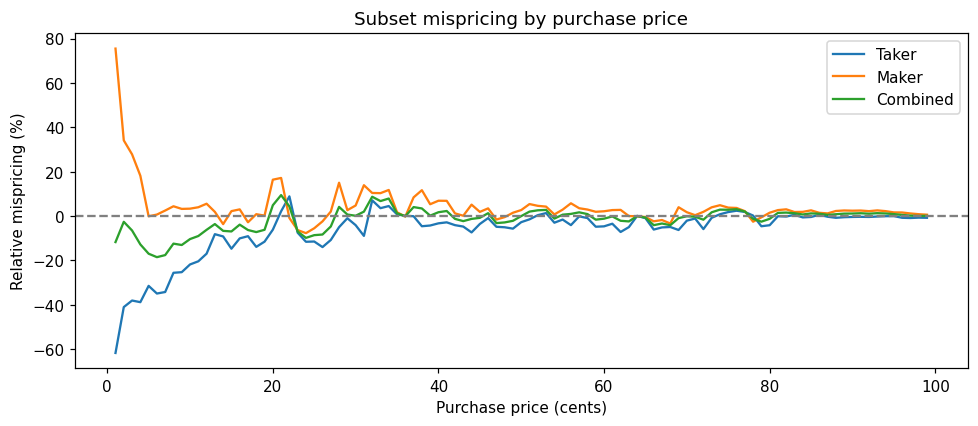

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, table in [("Taker", by_price.loc["Taker"]),
                     ("Maker", by_price.loc["Maker"]), ("Combined", combined)]:
    table = table.loc[table.index.to_series().between(1, 99)]
    ax.plot(table.index, 100 * table["excess_pp"] / table.index, label=label)
ax.axhline(0, color="gray", linestyle="--")
ax.set(xlabel="Purchase price (cents)", ylabel="Relative mispricing (%)",
       title="Subset mispricing by purchase price")
ax.legend()
plt.tight_layout()
plt.show()

### Maker versus taker returns at the same purchase price
Compare each role using its recorded purchase price. This is the same excess-return calculation
as the original analysis, displayed at each role's own cost rather than at complementary prices.


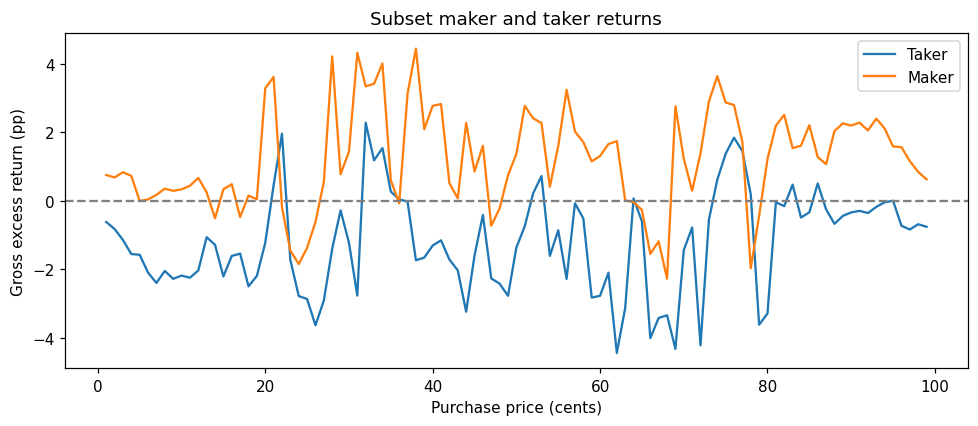

In [ ]:
taker_curve = by_price.loc["Taker", "excess_pp"].reindex(range(1, 100))
maker_curve = by_price.loc["Maker", "excess_pp"].reindex(range(1, 100))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(taker_curve.index, taker_curve, label="Taker")
ax.plot(taker_curve.index, maker_curve.to_numpy(), label="Maker")
ax.axhline(0, color="gray", linestyle="--")
ax.set(xlabel="Purchase price (cents)", ylabel="Gross excess return (pp)",
       title="Subset maker and taker returns")
ax.legend()
plt.tight_layout()
plt.show()

### YES versus NO at the same cost
This comparison uses contract-count weights, as in the original analysis. Each trade supplies a YES
and a NO position, including both roles. Negative values for cheap contracts indicate longshot
underperformance; compare YES and NO at the same cost rather than comparing complementary prices.

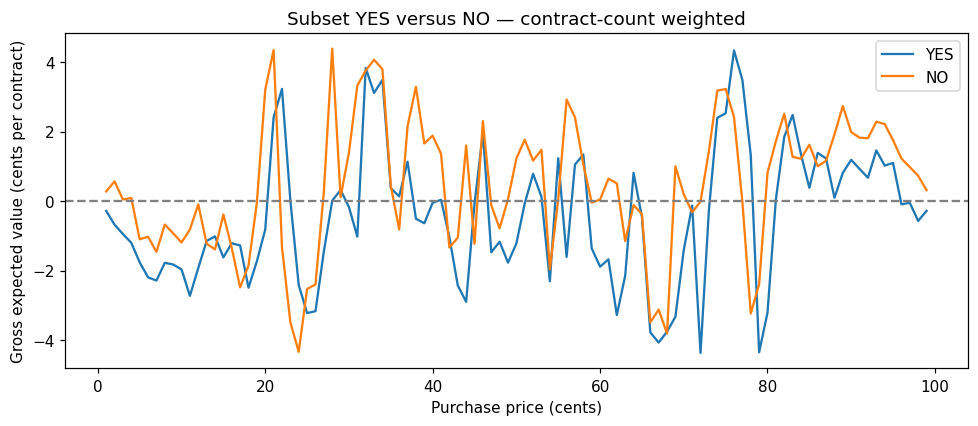

contracts  winning_contracts  ev_cents
side price                                        
no   0           2323                  1     0.043
     1      386668114            4948783     0.280
     2      128580202            3304604     0.570
     3      138121486            4208624     0.047
     4      131983413            5401305     0.092
     5      131456580            5127004    -1.100
     6      125842885            6262401    -1.024
     7      122364030            6778214    -1.461
     8      126794802            9289144    -0.674
     9      117558228            9491003    -0.927
     10     122434833           10787102    -1.190
     11     113436494           11550170    -0.818
     12     116203462           13834059    -0.095
     13     109042105           12836835    -1.228
     14     117898595           14866525    -1.390
     15     113769574           16627590    -0.385
     16     113028771           16558197    -1.350
     17     106137051           15408993    -2.482
     18     105103226           16970629    -1.853
     19     111760574           21186732    -0.043
     20     128037985           29714850     3.208
     21     121992978           30926696     4.351
     22     112348080           23229544    -1.324
     23     114874561           22413463    -3.489
     24     109678415           21565536    -4.337
     25     113980012           25612113    -2.529
     26     114171778           26945819    -2.399
     27     123555371           33685238     0.263
     28     116828219           37844104     4.393
     29     117177764           34112094     0.111
     30     130985593           41128436     1.399
     31     129374437           44411904     3.328
     32     126484440           45229994     3.759
     33     126626289           46942282     4.072
     34     131720454           49788950     3.799
     35     148189590           52518211     0.440
     36     145260592           51108474    -0.816
     37     143015628           55997668     2.155
     38     156194289           64493764     3.291
     39     140871349           57279810     1.661
     40     144891817           60684776     1.883
     41     149467301           63322283     1.365
     42     162685949           66157104    -1.334
     43     163353612           68522926    -1.052
     44     157897701           72005600     1.603
     45     167620455           73368732    -1.229
     46     162968650           78717810     2.302
     47     177304474           83124553    -0.118
     48     172692109           81539711    -0.783
     49     171912020           84331016     0.055
     50     181294721           92871880     1.227
     51     169494727           89443505     1.771
     52     181706701           96609780     1.168
     53     166364473           90634327     1.479
     54     164543770           85622358    -1.964
     55     160491467           88348931     0.049
     56     166760833           98262800     2.924
     57     161904770           96191887     2.413
     58     145071301           85671061     1.054
     59     136517799           80487525    -0.042
     60     156683901           94083979     0.047
     61     153884037           94865353     0.647
     62     152469713           95308425     0.510
     63     148140143           91624808    -1.150
     64     147594506           94291183    -0.115
     65     139222790           89980665    -0.369
     66     143692586           89825178    -3.488
     67     144010450           91988052    -3.124
     68     144496260           92748137    -3.813
     69     153216077          107253041     1.001
     70     144766440          101620180     0.196
     71     136751114           96655798    -0.320
     72     140186971          100914477    -0.014
     73     141576546          105392358     1.442
     74     137815515          106368076     3.181
     75     145440934          113777256     3.229
     76     140280773          110

In [ ]:
by_side = baseline.groupby(["side", "price"])[["contracts", "winning_contracts"]].sum()
by_side["ev_cents"] = (
    100 * by_side["winning_contracts"] / by_side["contracts"]
    - by_side.index.get_level_values("price")
)
fig, ax = plt.subplots(figsize=(9, 4))
for side in ["yes", "no"]:
    curve = by_side.loc[side].reindex(range(1, 100))
    ax.plot(curve.index, curve["ev_cents"], label=side.upper())
ax.axhline(0, color="gray", linestyle="--")
ax.set(xlabel="Purchase price (cents)", ylabel="Gross expected value (cents per contract)",
       title="Subset YES versus NO — contract-count weighted")
ax.legend()
plt.tight_layout()
plt.show()

# Include support counts so sparse price levels are visible when interpreting the curves.
display(by_side.round(3))

## 8. Prediction prototype: dependencies and parameters
Import modeling libraries and set the lookback window, cluster count, and minimum cluster size.


In [9]:
import numpy as np
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

HOURS, CLUSTERS, MIN_CLUSTER = 72, 8, 30



## 9. Eligible contracts and pre-cutoff trade history
Filter finalized contracts and construct historical features using only trades before each cutoff.


In [10]:
m = markets.loc[
    markets["status"].eq("finalized") & markets["result"].isin(["yes", "no"])
].copy()

assert m["ticker"].is_unique, "Market tickers must be unique."
m["close"] = pd.to_datetime(m["close_time"], utc=True, format="mixed")
m["cutoff"] = m["close"] - pd.Timedelta(hours=HOURS)
m["opened"] = pd.to_datetime(m["open_time"], utc=True, format="mixed")
m = m.loc[m["opened"].le(m["cutoff"])].dropna(subset=["event_ticker", "title"])
pieces = []
cutoffs = m.set_index("ticker")["cutoff"]

for t in pd.read_csv(
    TRADES_PATH,
    usecols=["ticker", "created_time", "yes_price", "count"],
    chunksize=500_000,
):
    t["time"] = pd.to_datetime(t["created_time"], utc=True, format="mixed")
    t = t.loc[t["time"].le(t["ticker"].map(cutoffs))].sort_values("time")
    pieces.append(t.groupby("ticker").agg(
        price=("yes_price", "last"), last_trade=("time", "last"),
        volume=("count", "sum"), trades=("count", "size"),
    ))

history = pd.concat(pieces).sort_values("last_trade").groupby(level=0).agg(
    price=("price", "last"), last_trade=("last_trade", "last"),
    volume=("volume", "sum"), trades=("trades", "sum"),
)
history = history.rename(columns={"volume": "pre_cutoff_volume"})
d = m.join(history, on="ticker", how="inner").reset_index(drop=True)



## 10. Target construction and numerical features
Compute realized deviations from observed prices and summarize historical trading activity.


In [11]:
d["price"] /= 100
d["target"] = d["result"].eq("yes").astype(float) - d["price"]
d["age_days"] = (d["cutoff"] - d["opened"]).dt.total_seconds() / 86400
d["stale_days"] = (d["cutoff"] - d["last_trade"]).dt.total_seconds() / 86400
d["log_volume"] = np.log1p(d["pre_cutoff_volume"])
d["log_trades"] = np.log1p(d["trades"])

print(f"Eligible contracts with pre-cutoff trades: {len(d):,}")


Eligible contracts with pre-cutoff trades: 45,648


## 11. Event-level temporal train/test split
Separate events chronologically and exclude training events that close after the test period begins.


In [12]:
events = d.groupby("event_ticker").agg(close=("close", "max"), cutoff=("cutoff", "min"))
events = events.sort_values("cutoff")
assert len(events) >= 10, "Too few eligible events for this prototype."

test_events = events.index[int(len(events) * 0.8):]
test_start = events.loc[test_events, "cutoff"].min()
train_events = events.index[events["close"].lt(test_start)]

train = d["event_ticker"].isin(train_events).to_numpy()
test = d["event_ticker"].isin(test_events).to_numpy()
assert train.sum() >= MIN_CLUSTER and test.sum(), "Insufficient data after temporal filtering."

print(f"Train: {train.sum():,} contracts | Test: {test.sum():,} contracts")


Train: 36,089 contracts | Test: 6,307 contracts


## 12. Text and numeric feature engineering
Construct wording features, standardized numeric variables, and reduced TF-IDF text representations.


In [13]:
text = d["title"].fillna("")
d["wording_score"] = (
    text.str.count(r"(?i)\b(win|wins|gain|gains|improve)\b")
    - text.str.count(r"(?i)\b(lose|loses|loss|decline|fail)\b")
)

features = ["price", "age_days", "stale_days", "log_volume", "log_trades", "wording_score"]
scaler = StandardScaler().fit(d.loc[train, features])
numeric = scaler.transform(d[features])

tfidf = TfidfVectorizer(stop_words="english", max_features=5000, min_df=2)
text_train = tfidf.fit_transform(text[train])
svd = TruncatedSVD(n_components=min(32, min(text_train.shape) - 1), random_state=42)
svd.fit(text_train)
semantic = svd.transform(tfidf.transform(text))



## 13. Contract clustering
Fit MiniBatchKMeans on training contracts and assign clusters to the full eligible dataset.


In [14]:
X = np.column_stack([semantic, numeric])
clustering = MiniBatchKMeans(
    n_clusters=min(CLUSTERS, train.sum()), random_state=42, n_init=10
).fit(X[train])
d["cluster"] = clustering.predict(X)


## 14. Cluster visualization and examples
Project contracts into two dimensions and inspect cluster sizes and representative market titles.


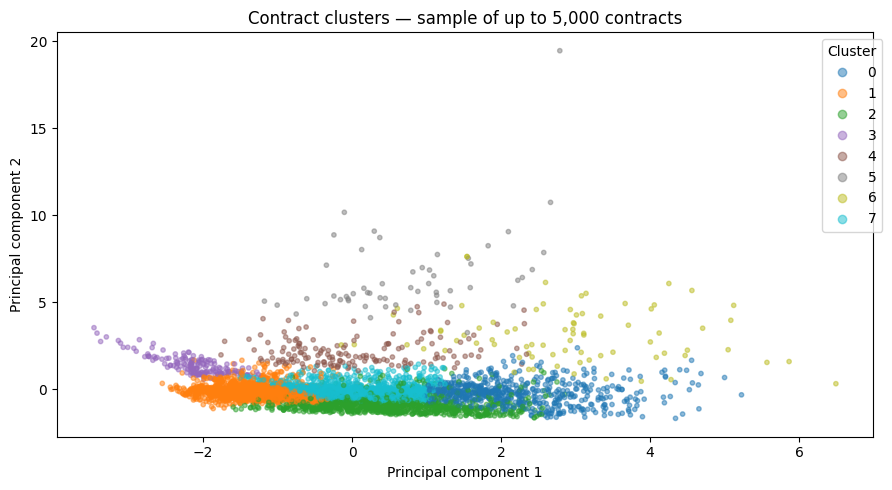

,contracts,example_titles
cluster,,
0,5731,"Will Trump's approval rating increase this week? | 2025 Game of the Year? | Top Netflix movie on Nov 17, 2025?"
1,17687,Real Betis vs Girona Winner? | Oviedo vs Vallecano Winner? | CR Flamengo RJ vs Red Bull Bragantino SP Winner?
2,8052,CR Flamengo RJ vs Red Bull Bragantino SP Winner? | SE Palmeiras SP vs Fluminense FC RJ Winner? | Leipzig vs Bremen Winner?
3,1303,"yes Dak Prescott: 175+,yes Bijan Robinson: 20+,yes Colston Loveland: 10+,yes Keenan Allen: 20+,yes Dawson Knox: 10+,yes Joshua Palmer: 10+,yes Baltimore wins by over 2.5 points..."
4,1524,Will Yukon Liberal Party win the 2025 Yukon general election? | Miss Universe 2025 Winner? | Will Andy win the Synthetix Mainnet Trading Competition?
5,420,Will Roy Cooper run for US Senate? | Who will win AL Reliever of the Year? | Who will win AL Cy Young?
6,787,2026 Grammy nominees for New Artist? | 2026 Grammy nominees for Record of the Year? | 2025 Game of the Year?
7,10144,"yes Atlanta,yes Cincinnati,yes New York G,yes Tennessee,yes Buffalo,yes Las Vegas | yes George Pickens,yes Javonte Williams,yes Tre Tucker,yes Dak Prescott: 225+,yes Geno Smith..."


In [15]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Fit the projection on training data and display a sample of contracts.
projection = PCA(n_components=2).fit(X[train])
sample = d.sample(min(5000, len(d)), random_state=42)
points = projection.transform(X[sample.index])

plt.figure(figsize=(9, 5))
scatter = plt.scatter(
    points[:, 0], points[:, 1],
    c=sample["cluster"], cmap="tab10", s=10, alpha=0.5,
)
plt.legend(*scatter.legend_elements(), title="Cluster", bbox_to_anchor=(1.02, 1))
plt.title("Contract clusters — sample of up to 5,000 contracts")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.tight_layout()
plt.show()

# Show all cluster sizes and three distinct example titles per cluster.
summary = d.groupby("cluster").agg(
    contracts=("ticker", "size"),
    example_titles=("title", lambda s: " | ".join(s.drop_duplicates().head(3))),
)

with pd.option_context("display.max_colwidth", 180):
    display(summary)


## 15. Global and cluster-specific predictive models
Fit a global Ridge baseline and separate cluster models with historical-mean fallback.


In [16]:
global_model = Ridge(alpha=10).fit(X[train], d.loc[train, "target"])
d["global_prediction"] = global_model.predict(X)
d["prediction"], d["historical_mean"] = np.nan, np.nan

for cluster in sorted(d["cluster"].unique()):
    fit = train & d["cluster"].eq(cluster).to_numpy()
    predict = test & d["cluster"].eq(cluster).to_numpy()
    historical = d.loc[fit, "target"].mean() if fit.any() else d.loc[train, "target"].mean()
    d.loc[predict, ["historical_mean", "prediction"]] = historical

    if fit.sum() >= MIN_CLUSTER:
        model = Ridge(alpha=10).fit(X[fit], d.loc[fit, "target"] - historical)
        if predict.any():
            d.loc[predict, "prediction"] = historical + model.predict(X[predict])



## 16. Probability bounds
Clip implied YES probabilities to the interval [0, 1] and convert them back to deviations.


In [17]:
# A predicted YES deviation implies a YES probability of price + deviation.
for column in ["prediction", "global_prediction", "historical_mean"]:
    d[column] = (d["price"] + d[column]).clip(0, 1) - d["price"]


## 17. Held-out evaluation
Compare baseline and predictive methods using event-averaged MAE and RMSE, then inspect results by cluster.


In [18]:
heldout = d.loc[test].copy()
heldout["zero_prediction"] = 0
scores = {}

for name, column in {
    "No deviation": "zero_prediction",
    "Historical cluster mean": "historical_mean",
    "Global model": "global_prediction",
    "Separate cluster models": "prediction",
}.items():
    error = heldout[column] - heldout["target"]
    event_errors = pd.DataFrame({
        "event": heldout["event_ticker"], "absolute": error.abs(), "squared": error**2,
    }).groupby("event").mean()
    scores[name] = {
        "MAE (pp)": event_errors["absolute"].mean() * 100,
        "RMSE (pp)": np.sqrt(event_errors["squared"].mean()) * 100,
    }

display(pd.DataFrame(scores).T.round(2))
display(heldout.groupby("cluster").agg(
    contracts=("ticker", "size"),
    predicted_deviation=("prediction", "mean"),
    realized_deviation=("target", "mean"),
).round(4))

,MAE (pp),RMSE (pp)
No deviation,18.88,32.00
Historical cluster mean,18.69,32.06
Global model,19.38,32.18
Separate cluster models,19.85,32.46


,contracts,predicted_deviation,realized_deviation
cluster,,,
0,386,-0.0061,0.0023
1,3600,0.0007,0.0208
2,791,-0.0432,-0.0459
3,321,0.0056,0.0480
4,105,-0.0152,-0.0256
5,57,-0.0012,-0.0318
6,15,0.0108,-0.0020
7,1032,-0.0015,-0.0093
